In [23]:
import pandas as pd
df = pd.read_csv("../data/bank-additional-full.csv", sep=";")

In [24]:
line_drop = df.drop(columns=["y","duration"])
print(line_drop)

       age          job  marital            education  default housing loan  \
0       56    housemaid  married             basic.4y       no      no   no   
1       57     services  married          high.school  unknown      no   no   
2       37     services  married          high.school       no     yes   no   
3       40       admin.  married             basic.6y       no      no   no   
4       56     services  married          high.school       no      no  yes   
...    ...          ...      ...                  ...      ...     ...  ...   
41183   73      retired  married  professional.course       no     yes   no   
41184   46  blue-collar  married  professional.course       no      no   no   
41185   56      retired  married    university.degree       no     yes   no   
41186   44   technician  married  professional.course       no      no   no   
41187   74      retired  married  professional.course       no     yes   no   

         contact month day_of_week  campaign  pdays

In [25]:
print(df.columns.tolist())

['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']


In [26]:
y = (df["y"]=="yes").astype(int)
print(y.value_counts())

y
0    36548
1     4640
Name: count, dtype: int64


In [27]:
x = df.drop(columns=["y","duration"])
x = pd.get_dummies(x)
print(x.shape)

(41188, 62)


In [28]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(
    x,y,test_size=0.2,random_state=42
)
print(x_train.shape,x_test.shape,y_train.shape,y_test.shape)

(32950, 62) (8238, 62) (32950,) (8238,)


In [29]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train_s = scaler.fit_transform(x_train)
x_test_s = scaler.transform(x_test)

In [30]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000)
model.fit(x_train_s,y_train)
prob = model.predict_proba(x_test_s)[:,1]

In [31]:
from sklearn.metrics import roc_auc_score
auc = roc_auc_score(y_test,prob)
print("AUC",auc)

AUC 0.7801198833385444


In [32]:
print(prob[:10])
print("最小",prob.min(),"最大",prob.max())

[0.05977979 0.02120898 0.05891104 0.04897132 0.06130063 0.08664707
 0.02983846 0.03552618 0.05790859 0.05400693]
最小 0.0038942341319299113 最大 0.889734355912745


In [33]:
import pandas as pd
df = pd.read_csv("../data/bank-additional-full.csv", sep=";")

In [34]:
mirror_group = df.drop(columns=["y"])
print(mirror_group)

       age          job  marital            education  default housing loan  \
0       56    housemaid  married             basic.4y       no      no   no   
1       57     services  married          high.school  unknown      no   no   
2       37     services  married          high.school       no     yes   no   
3       40       admin.  married             basic.6y       no      no   no   
4       56     services  married          high.school       no      no  yes   
...    ...          ...      ...                  ...      ...     ...  ...   
41183   73      retired  married  professional.course       no     yes   no   
41184   46  blue-collar  married  professional.course       no      no   no   
41185   56      retired  married    university.degree       no     yes   no   
41186   44   technician  married  professional.course       no      no   no   
41187   74      retired  married  professional.course       no     yes   no   

         contact month day_of_week  duration  campa

In [35]:
print(mirror_group.columns.to_list())

['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


In [36]:
y = (df["y"]=="yes").astype(int)
print(y.value_counts())

y
0    36548
1     4640
Name: count, dtype: int64


In [37]:
x2 = df.drop(columns=["y"])
x2 = pd.get_dummies(x2)
print(x2.shape)

(41188, 63)


In [38]:
from sklearn.model_selection import train_test_split
x_train2,x_test2,y_train2,y_test2 = train_test_split(
    x2,y,test_size=0.2,random_state=42
)
print(x_train2.shape,x_test2.shape,y_train2.shape,y_test2.shape)

(32950, 63) (8238, 63) (32950,) (8238,)


In [39]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train2_s = scaler.fit_transform(x_train2)
x_test2_s = scaler.transform(x_test2)

In [40]:
from sklearn.linear_model import LogisticRegression
model2 = LogisticRegression(max_iter=1000)
model2.fit(x_train2_s,y_train2)
prob2 = model2.predict_proba(x_test2_s)[:,1]

In [41]:
from sklearn.metrics import roc_auc_score
auc2 = roc_auc_score(y_test2,prob2)
print("不去duration的AUC：",auc2)

不去duration的AUC： 0.9348921877391241


In [42]:
print(prob2[:10])
print("最小",prob2.min(),"最大",prob2.max())

[0.06290845 0.0104734  0.0130448  0.03795119 0.01989275 0.16491105
 0.01172302 0.00690877 0.01643516 0.00986487]
最小 0.0010978508046896522 最大 0.9999988282422266


In [43]:
lift_analysis = pd.DataFrame({"真实":y_test.values,"概率":prob})
sort_lift_analysis = lift_analysis.sort_values("概率",ascending = False)
print(lift_analysis)
print(sort_lift_analysis)

      真实        概率
0      0  0.059780
1      0  0.021209
2      0  0.058911
3      0  0.048971
4      0  0.061301
...   ..       ...
8233   1  0.026433
8234   0  0.045379
8235   0  0.072773
8236   1  0.090849
8237   0  0.036995

[8238 rows x 2 columns]
      真实        概率
7211   0  0.889734
416    1  0.885131
4502   1  0.882217
2098   1  0.882109
1950   0  0.878187
...   ..       ...
6077   0  0.009682
732    0  0.009283
7815   0  0.008724
5671   0  0.005247
118    0  0.003894

[8238 rows x 2 columns]


In [46]:
top20 = int(len(sort_lift_analysis)*0.2)
top20_consumer = sort_lift_analysis.head(top20)
print("前20%人数：",top20)
print("其中真实买家:",top20_consumer["真实"].sum())
print("所有真实买家：",sort_lift_analysis["真实"].sum())

前20%人数： 1647
其中真实买家: 569
所有真实买家： 935


In [48]:
capture_rate = top20_consumer["真实"].sum()/sort_lift_analysis["真实"].sum()
print("捕获率：",capture_rate)

捕获率： 0.6085561497326203


In [53]:
rate_list = [0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0]
capture_rate_list = []
for rate in rate_list:
    n = int(len(sort_lift_analysis)*rate)
    current_part = sort_lift_analysis.head(n)
    capture_rate = current_part["真实"].sum()/sort_lift_analysis["真实"].sum()
    capture_rate_list.append(capture_rate)
print(capture_rate_list)

[np.float64(0.0), np.float64(0.413903743315508), np.float64(0.6085561497326203), np.float64(0.6898395721925134), np.float64(0.7497326203208556), np.float64(0.8074866310160428), np.float64(0.8502673796791443), np.float64(0.8962566844919786), np.float64(0.9347593582887701), np.float64(0.9647058823529412), np.float64(1.0)]


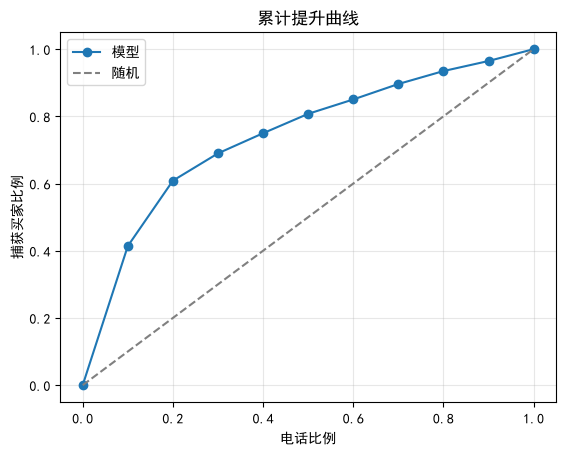

In [54]:
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False

plt.plot(rate_list,capture_rate_list,marker="o",label="模型")
plt.plot([0,1],[0,1],"--",color="gray",label="随机")
plt.xlabel("电话比例")
plt.ylabel("捕获买家比例")
plt.title("累计提升曲线")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier

model3 = HistGradientBoostingClassifier(random_state = 42)
model3.fit(x_train,y_train)
prob3 = model3.predict_proba(x_test)[:,1]
auc3 = orc_auc_score(y_test,prob3)
print("梯度提升树 :",auc3)